# 第 2 章 參考值與實驗設計：程式練習

**目標**：校正線的好壞，一半取決於「參考值準不準」，另一半取決於「實驗怎麼設計」。本章用第 1 章同一組資料：

| 節 | 內容 |
|---|---|
| 0 | 載入資料、定義四組參考值（標示、滴定、Atago 11/02、Atago 11/03） |
| 1 | 滴定計算：手算一次，再寫成函式 |
| 2 | 比值檢驗：比例誤差 vs 非比例誤差 |
| 3 | NIR 對各參考值的線性 |
| 4 | 重複性與填樣誤差 |
| 5 | 實驗設計模擬（蒙地卡羅） |
| 6 | 滴定的改進清單 |
| 7 | 自我驗證（PASS/FAIL 表） |

只用 numpy、pandas、matplotlib、scipy（scipy 只用 `savgol_filter` 當二階導數）。圖上文字一律用英文（Colab 沒有中文字型）。
每節結尾有「動手改改看」。

> **本機 Jupyter 版**：請在 `teaching/exercises/` 目錄下開啟，資料讀自 `../data/spectra_long.csv`。
> 需要套件：numpy、pandas、matplotlib、scipy。Colab 請改開 `ch02_reference_design_colab.ipynb`。

In [1]:
DATA_PATH = '../data/spectra_long.csv'   # 本機版：讀上一層 data 資料夾

## 0. 載入資料、定義參考值

四個樣品（水＋三瓶醋）有四組參考值：

| 樣品 | 標示 | Atago 11/02 | Atago 11/03 | 滴定 |
|---|---|---|---|---|
| 水 | 0 | 0 | 0 | 0 |
| 3% 瓶 | 3 | 3.32 | 3.01 | 第 1 節算出 |
| 5% 瓶 | 5 | 4.87 | 4.12 | 第 1 節算出 |
| 10% 瓶 | 10 | 7.45 | 6.86 | 第 1 節算出 |

In [2]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter

np.set_printoptions(precision=5, linewidth=130)
plt.rcParams['figure.dpi'] = 90

# ---- 可調整的參數 ----
SG_WIN    = 9           # 二階導數 SG 視窗
F_TITER   = 1.07875     # NaOH 力價 f
SIG_FILL  = 0.05        # 第 5 節：填樣/光徑相對誤差（標準差）
SIG_NOISE = 1.2e-4      # 第 5 節：加成性雜訊（二階導數單位）
N_SIM     = 2000        # 蒙地卡羅次數
SEED      = 2026
TRUE_SLOPE = -9.852e-4  # 1 mm、2258 nm 校正線（每 % 酸度；二階導數單位為每點^2）
TRUE_ICPT  = 9.087e-3

ACID_ATAGO_1102 = np.array([0, 3.32, 4.87, 7.45])
ACID_ATAGO_1103 = np.array([0, 3.01, 4.12, 6.86])
ACID_LABEL      = np.array([0, 3, 5, 10.])
SAMPLES = ['water', 'vinegar_3%', 'vinegar_5%', 'vinegar_10%']

In [3]:
df = pd.read_csv(DATA_PATH)
main = df[df['replicate'] == 1]            # 注意：用 d['sample']，d.sample 是 pandas 的方法
wl = np.sort(main['wavelength_nm'].unique()); n_wl = len(wl)

def get_spec(p):
    rows = []
    for s in SAMPLES:
        h = main[(np.isclose(main['path_mm'], p)) & (main['sample'] == s)].sort_values('wavelength_nm')
        assert len(h) == n_wl
        rows.append(h['absorbance'].values)
    return np.array(rows)

spec1, spec025 = get_spec(1), get_spec(0.25)
D2_1 = savgol_filter(spec1, SG_WIN, 2, deriv=2, axis=1)     # 4 x 142，單位：每點^2
i2258 = int(np.argmin(np.abs(wl - 2258))); i1670 = int(np.argmin(np.abs(wl - 1670)))
sig2258, sig1670 = D2_1[:, i2258], D2_1[:, i1670]

def fit_line(x, y):
    x = np.asarray(x, float); y = np.asarray(y, float)
    sxx = np.sum((x - x.mean())**2)
    slope = np.sum((x - x.mean()) * (y - y.mean())) / sxx
    icpt = y.mean() - slope * x.mean()
    pred = icpt + slope * x
    return slope, icpt, 1 - np.sum((y - pred)**2) / np.sum((y - y.mean())**2)

print(df.shape, ' spec1:', spec1.shape)
print('1 mm 2258 nm 二階導數（水, 3%, 5%, 10%）：', sig2258)

(2982, 7)  spec1: (4, 142)
1 mm 2258 nm 二階導數（水, 3%, 5%, 10%）： [0.00851 0.00631 0.00517 0.00095]


### 動手改改看（第 0 節）
1. 為什麼這章把 Atago 分成 11/02 與 11/03 兩組？兩組同一瓶的差距有多大？
2. 印出 `SAMPLES` 的順序，確認第 4 列是 10% 標示的瓶子。

## 1. 滴定計算

步驟：**取 10 mL 醋稀釋到 100 mL，再取 25 mL 滴定**；NaOH 力價 f = 1.07875；每 mL 0.1 N NaOH 相當 0.006 g 醋酸。

酸度 (g/100 mL) = V × f × 0.006 × (100/25) ÷ 10 × 100

先手算 3% 瓶（用掉 8.8 mL）：

In [4]:
V1 = 8.8
g25 = V1 * F_TITER * 0.006
print('25 mL 中醋酸 = %.6f g' % g25)
print('x 4（還原到 100 mL 稀釋液）= %.6f g' % (g25 * 4))
print('/ 10 mL 原液 * 100 = %.4f g/100 mL' % (g25 * 4 / 10 * 100))

def titration(V, f=F_TITER, aliquot=25, dil_vol=100, sample_mL=10):
    return np.asarray(V, float) * f * 0.006 * (dil_vol / aliquot) / sample_mL * 100

V_NAOH = np.array([8.8, 17, 44])
ACID_TITR = titration(V_NAOH)
print(pd.DataFrame({'label': ['3%', '5%', '10%'], 'V_mL': V_NAOH, 'titration_pct': ACID_TITR.round(3)}).to_string(index=False))
ACID_TITR_X = np.r_[0, ACID_TITR]

25 mL 中醋酸 = 0.056958 g
x 4（還原到 100 mL 稀釋液）= 0.227832 g
/ 10 mL 原液 * 100 = 2.2783 g/100 mL
label  V_mL  titration_pct
   3%   8.8          2.278
   5%  17.0          4.401
  10%  44.0         11.392


### 動手改改看（第 1 節）
1. 把 `F_TITER` 改成 1.0，三個結果各變成多少？彼此的比例變了嗎？
2. 若 3% 瓶實際用量是 8.08 mL（手稿筆誤），酸度會差多少？
3. 把 `aliquot` 改成 10（取 10 mL 稀釋液），同樣 10% 瓶要用掉幾 mL？（第 6 節會正式算。）

## 2. 比值檢驗：比例誤差 vs 非比例誤差

滴定 ÷ Atago(11/03) = 0.757、1.068、1.661。

- **比例誤差**（例如 NaOH 力價 f 錯 5%）：三瓶滴定值**同乘 1.05**，比值也一起乘 1.05，
  「三瓶之間的相對關係」不變；校正線只是整體縮放，**不影響線性、只影響絕對值**。
- 實際比值是 0.76 → 1.07 → 1.66，**不是常數**，所以**不能用力價誤差解釋**。這是濃度相關的非比例誤差：Atago 在高濃度讀低。

Atago 以導電度換算酸度。醋酸是弱酸，導電度不隨濃度線性增加，也受基質影響，**「可能」**是原因，但各型號的量程與換算不同，**需查對儀器型號說明書**。
另外，兩次 Atago 讀值相差 8–15%（例如 4.87 vs 4.12），同一瓶醋的再現性也不佳。

實際比值 滴定/Atago(11/03)： [0.757 1.068 1.661]
Atago 11/02 相對 11/03 高出： [10.3 18.2  8.6] %
f 錯 5% 後的滴定值： [ 2.392  4.621 11.961]
f 錯 5% 後的比值    ： [0.795 1.122 1.744]
比值除以第一個（相對形狀）：實際 [1.    1.411 2.194] / f 錯 5%： [1.    1.411 2.194] （完全相同）
R2：真實滴定 0.9898，f 錯 5% 0.9898（比例誤差不改變 R2）


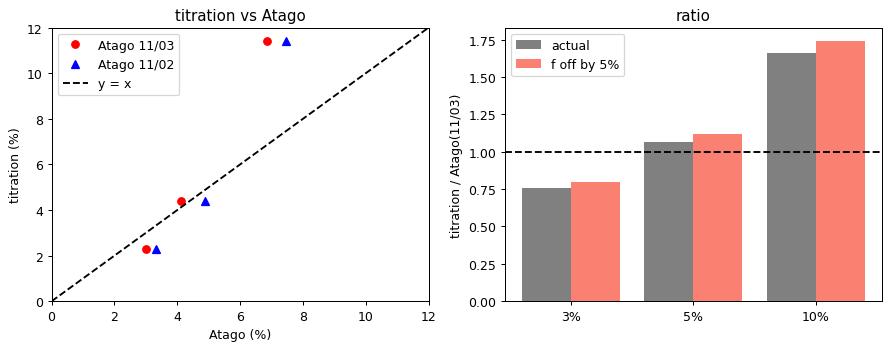

In [5]:
ratio_real = ACID_TITR / ACID_ATAGO_1103[1:]
print('實際比值 滴定/Atago(11/03)：', ratio_real.round(3))
print('Atago 11/02 相對 11/03 高出：', (100 * (ACID_ATAGO_1102[1:] / ACID_ATAGO_1103[1:] - 1)).round(1), '%')

ACID_F5 = titration(V_NAOH, f=F_TITER * 1.05)           # 力價錯 5%
rr5 = ACID_F5 / ACID_ATAGO_1103[1:]
print('f 錯 5% 後的滴定值：', ACID_F5.round(3))
print('f 錯 5% 後的比值    ：', rr5.round(3))
print('比值除以第一個（相對形狀）：實際', (ratio_real / ratio_real[0]).round(3), '/ f 錯 5%：', (rr5 / rr5[0]).round(3), '（完全相同）')
print('R2：真實滴定 %.4f，f 錯 5%% %.4f（比例誤差不改變 R2）' %
      (fit_line(ACID_TITR_X, sig2258)[2], fit_line(np.r_[0, ACID_F5], sig2258)[2]))

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(ACID_ATAGO_1103[1:], ACID_TITR, 'ro', label='Atago 11/03')
ax[0].plot(ACID_ATAGO_1102[1:], ACID_TITR, 'b^', label='Atago 11/02')
ax[0].plot([0, 12], [0, 12], 'k--', label='y = x')
ax[0].set_xlim(0, 12); ax[0].set_ylim(0, 12)
ax[0].set_xlabel('Atago (%)'); ax[0].set_ylabel('titration (%)'); ax[0].set_title('titration vs Atago'); ax[0].legend()
xx = np.arange(3)
ax[1].bar(xx - 0.2, ratio_real, 0.4, color='gray', label='actual')
ax[1].bar(xx + 0.2, rr5, 0.4, color='salmon', label='f off by 5%')
ax[1].axhline(1, color='k', ls='--'); ax[1].set_xticks(xx); ax[1].set_xticklabels(['3%', '5%', '10%'])
ax[1].set_ylabel('titration / Atago(11/03)'); ax[1].set_title('ratio'); ax[1].legend()
plt.tight_layout(); plt.show()

### 動手改改看（第 2 節）
1. 把力價誤差改成 −8%，比值還是不是常數？
2. 若 Atago 只是單純整體偏低 20%（比例誤差），比值會長怎樣？和實際觀察一致嗎？
3. 兩次 Atago 讀值相差 8–15%，這對「用 Atago 當校正參考值」有什麼影響？

## 3. NIR 對各參考值的線性

1 mm、2258 nm 與 1670 nm 的二階導數，對四組參考值（x 含水 = 0，n = 4）做迴歸，看 R²：

| 參考值 | 2258 nm R² | 1670 nm R² |
|---|---|---|
| 標示 | 0.9955 | 0.9983 |
| 滴定 | 0.9898 | 0.9866 |
| Atago 11/03 | 0.9555 | 0.9633 |
| Atago 11/02 | 0.9342 | 0.9448 |

       reference  R2_2258  R2_1670
label (0/3/5/10)   0.9955   0.9983
       titration   0.9898   0.9866
     Atago 11/03   0.9555   0.9633
     Atago 11/02   0.9342   0.9448


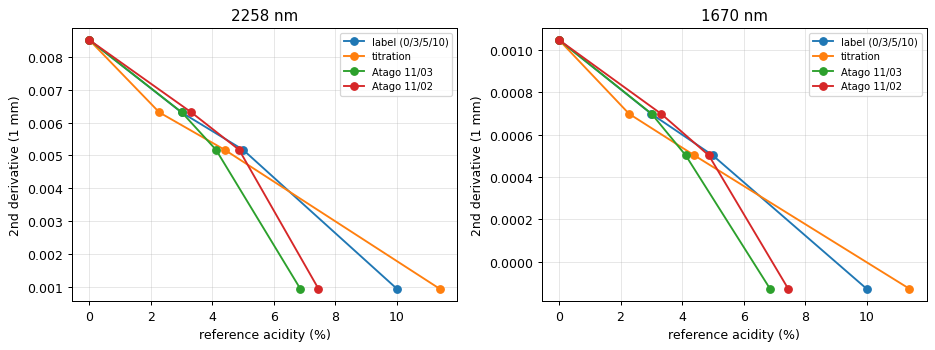

In [6]:
REFS = {'label (0/3/5/10)': ACID_LABEL, 'titration': ACID_TITR_X,
        'Atago 11/03': ACID_ATAGO_1103, 'Atago 11/02': ACID_ATAGO_1102}
R2T = pd.DataFrame([{'reference': k, 'R2_2258': fit_line(v, sig2258)[2], 'R2_1670': fit_line(v, sig1670)[2]}
                    for k, v in REFS.items()])
print(R2T.to_string(index=False, float_format=lambda v: '%.4f' % v))

fig, ax = plt.subplots(1, 2, figsize=(10.5, 4))
for c, (b, sg) in enumerate([('2258', sig2258), ('1670', sig1670)]):
    for k, v in REFS.items():
        ax[c].plot(v, sg, 'o-', label=k)
    ax[c].set_xlabel('reference acidity (%)'); ax[c].set_ylabel('2nd derivative (1 mm)')
    ax[c].set_title('%s nm' % b); ax[c].legend(fontsize=8); ax[c].grid(alpha=0.3)
plt.tight_layout(); plt.show()

**重點**：兩個**獨立**的吸收帶（2258 與 1670 nm）都與滴定、標示較一致，與 Atago 較差。
但 n = 4、每瓶只填一次樣，R² 0.93 與 0.99 的差異只能當作**「一致的跡象」**，不是統計上的證明。

### 動手改改看（第 3 節）
1. 四組參考值各自去掉水（x = 0），只用三瓶醋重算 R²（n = 3），排名會變嗎？
2. 為什麼 n = 4 時 R² 0.99 vs 0.93 仍不能說「統計上顯著不同」？
3. 兩個吸收帶獨立測量，卻都偏好滴定與標示，這支持了什麼推論？還缺什麼？

## 4. 重複性與填樣誤差

- 0.25 mm 的水量了兩次（replicate 1、2）。兩次差值的**母體標準差**代表儀器重複性。
- 0.25 mm 的 4.87% 光譜水帶比水小：報告稱「整體縮小約 15%」。醋含水較少，水帶本來就會稍低，
  但縮小得比預期多，**疑似填樣或光徑誤差**。
- 同一個絕對光徑/填樣誤差 δb，相對誤差 = δb / b，**約與 1/光徑成正比**：光徑越短越吃虧。

0.25 mm 水兩次量測差值的母體標準差 = 0.001225 AU -> 儀器很穩
0.25 mm：1940 nm 帶 (1943.0 nm) 4.87% 醋 1.052 vs 水 1.270 -> 比值 0.828（-17%）
          1450 nm 帶 (1448.3 nm) 4.87% 醋 0.557 vs 水 0.621 -> 比值 0.897（-10%）
 path_mm  rel_err_pct
    0.25         16.0
    0.50          8.0
    1.00          4.0
    2.00          2.0
    5.00          0.8


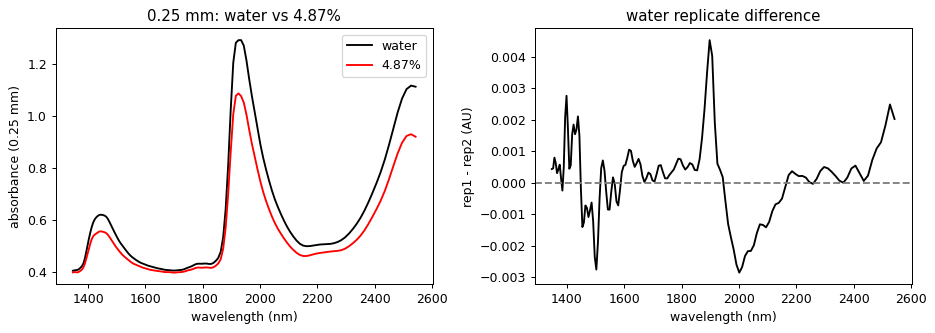

In [7]:
def pop_std(v):
    v = np.asarray(v, float).ravel()
    return float(np.sqrt(np.mean((v - v.mean())**2)))        # 除以 N（np.std）

w1 = main[np.isclose(main['path_mm'], 0.25) & (main['sample'] == 'water')].sort_values('wavelength_nm')
w2 = df[(df['replicate'] == 2) & np.isclose(df['path_mm'], 0.25) & (df['sample'] == 'water')].sort_values('wavelength_nm')
assert len(w1) == n_wl and len(w2) == n_wl
REP_SD = pop_std(w1['absorbance'].values - w2['absorbance'].values)
print('0.25 mm 水兩次量測差值的母體標準差 = %.6f AU -> 儀器很穩' % REP_SD)

i1940 = int(np.argmin(np.abs(wl - 1940))); i1450 = int(np.argmin(np.abs(wl - 1450)))
water, v5 = spec025[0], spec025[2]
R1940, R1450 = v5[i1940] / water[i1940], v5[i1450] / water[i1450]
print('0.25 mm：1940 nm 帶 (%.1f nm) 4.87%% 醋 %.3f vs 水 %.3f -> 比值 %.3f（%.0f%%）' %
      (wl[i1940], v5[i1940], water[i1940], R1940, 100 * (R1940 - 1)))
print('          1450 nm 帶 (%.1f nm) 4.87%% 醋 %.3f vs 水 %.3f -> 比值 %.3f（%.0f%%）' %
      (wl[i1450], v5[i1450], water[i1450], R1450, 100 * (R1450 - 1)))

db = 0.04     # 假設絕對光徑（或填樣）誤差 0.04 mm
print(pd.DataFrame({'path_mm': [0.25, 0.5, 1, 2, 5],
                    'rel_err_pct': [round(100 * db / b, 2) for b in [0.25, 0.5, 1, 2, 5]]}).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.8))
ax[0].plot(wl, water, 'k', label='water'); ax[0].plot(wl, v5, 'r', label='4.87%')
ax[0].set_xlabel('wavelength (nm)'); ax[0].set_ylabel('absorbance (0.25 mm)'); ax[0].set_title('0.25 mm: water vs 4.87%'); ax[0].legend()
ax[1].plot(wl, w1['absorbance'].values - w2['absorbance'].values, 'k')
ax[1].axhline(0, ls='--', color='gray'); ax[1].set_xlabel('wavelength (nm)'); ax[1].set_ylabel('rep1 - rep2 (AU)')
ax[1].set_title('water replicate difference')
plt.tight_layout(); plt.show()

### 動手改改看（第 4 節）
1. 1 mm 沒有重複量測（想想為什麼不能算同樣的差值），需要補什麼實驗？
2. `db` 改成 0.01 mm，0.25 mm 與 1 mm 的相對誤差各是多少？
3. 4.87% 的 1450 nm 與 1940 nm 縮小幅度不同（約 −10% vs −17%），若是純填樣誤差，你預期會一樣還是不同？

## 5. 實驗設計模擬（蒙地卡羅，固定亂數種子）

以 1 mm、2258 nm 的真實校正線（斜率 −9.852e-4 /%、截距 9.087e-3）當「真值」。每次填樣的訊號：

**訊號 = (截距 + 斜率·c) × (1 + ε_fill) + ε_noise**，ε_fill ~ N(0, 0.05)（填樣/光徑相對誤差 5%），ε_noise ~ N(0, 1.2e-4)。

比較兩種設計，各模擬 2000 次：

- **A**：現況，4 個濃度 (0, 3.32, 4.87, 7.45) × 1 次填樣。
- **B**：同一瓶稀釋出 0, 1, …, 7 %（8 個濃度）× 3 次填樣。

報告斜率的相對標準差與 RMSECV 的中位數。B 的 RMSECV 用「留一**濃度**」交叉驗證（每次把同一濃度的 3 次填樣一起留下）。
這節是模擬，數字會隨亂數種子改變；R 與 Python 亂數不同，數字不必相同，但結論應一致。

             design  n  slope_RSD_pct  RMSECV_median_pct
 A: 4 conc x 1 fill  4           6.90              0.378
B: 8 conc x 3 fills 24           3.14              0.342
B / A 斜率相對標準差比值 = 0.455（理論約 0.48：B 的 Sxx 約為 A 的 4.3 倍）


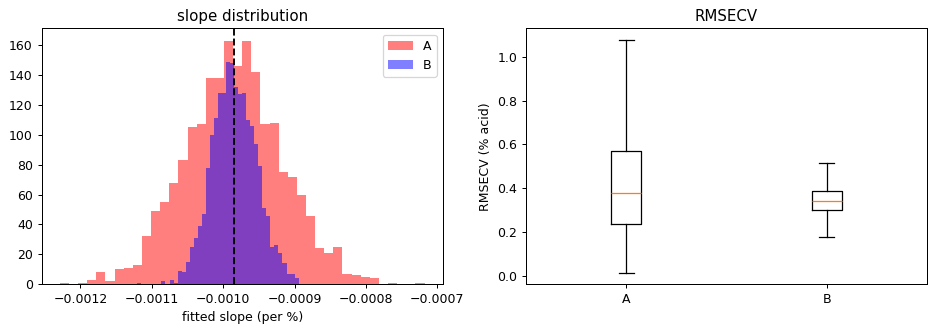

In [8]:
def cv_group(x, y, grp):
    e = []
    for g in np.unique(grp):
        tr = grp != g
        s, b0, _ = fit_line(x[tr], y[tr])
        e.extend(x[~tr] - (y[~tr] - b0) / s)
    return float(np.sqrt(np.mean(np.square(e))))

def sim_design(conc, nrep, nsim=N_SIM, seed=SEED):
    rng = np.random.default_rng(seed)
    x = np.repeat(np.asarray(conc, float), nrep); grp = np.repeat(np.arange(len(conc)), nrep)
    slopes, rm = np.empty(nsim), np.empty(nsim)
    for s in range(nsim):
        y = (TRUE_ICPT + TRUE_SLOPE * x) * (1 + rng.normal(0, SIG_FILL, x.size)) + rng.normal(0, SIG_NOISE, x.size)
        slopes[s] = fit_line(x, y)[0]
        rm[s] = cv_group(x, y, grp)
    return slopes, rm

slA, rmA = sim_design([0, 3.32, 4.87, 7.45], 1)
slB, rmB = sim_design(np.arange(8), 3)
rsdA, rsdB = slA.std(ddof=1) / abs(TRUE_SLOPE), slB.std(ddof=1) / abs(TRUE_SLOPE)
medA, medB = float(np.median(rmA)), float(np.median(rmB))
print(pd.DataFrame({'design': ['A: 4 conc x 1 fill', 'B: 8 conc x 3 fills'], 'n': [4, 24],
                    'slope_RSD_pct': [round(100 * rsdA, 2), round(100 * rsdB, 2)],
                    'RMSECV_median_pct': [round(medA, 3), round(medB, 3)]}).to_string(index=False))
print('B / A 斜率相對標準差比值 = %.3f（理論約 0.48：B 的 Sxx 約為 A 的 4.3 倍）' % (rsdB / rsdA))

fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.8))
ax[0].hist(slA, bins=40, alpha=0.5, color='r', label='A'); ax[0].hist(slB, bins=40, alpha=0.5, color='b', label='B')
ax[0].axvline(TRUE_SLOPE, color='k', ls='--'); ax[0].set_xlabel('fitted slope (per %)'); ax[0].set_title('slope distribution'); ax[0].legend()
ax[1].boxplot([rmA, rmB], showfliers=False); ax[1].set_xticklabels(['A', 'B']); ax[1].set_ylabel('RMSECV (% acid)'); ax[1].set_title('RMSECV')
plt.tight_layout(); plt.show()

**結論**：B 的斜率不確定度明顯較小（Sxx 約為 A 的 4.3 倍，標準差約為 A 的 0.48 倍）。
同濃度重複填樣還能把「填樣誤差」與「濃度效應」分開，A 設計做不到。

### 動手改改看（第 5 節）
1. 把 `SIG_FILL` 改成 0.02 或 0.10，A 與 B 的斜率相對標準差怎麼變？比值 B/A 變不變？
2. 設計 C：8 個濃度 × 1 次填樣。與 A、B 比較，多重複與多濃度哪個貢獻較大？
3. 把 `SIG_NOISE` 調成 1e-3（雜訊大 10 倍），結論還成立嗎？

## 6. 滴定的改進清單

1. **KHP 標定 NaOH**：NaOH 吸濕、吸 CO₂，不是一級標準品。力價錯屬比例誤差。
2. **三重複＋空白試驗**。
3. **10% 瓶用掉 44 mL，接近 50 mL 滴定管**：改取 10 mL 稀釋液，或稀釋更多倍。
4. **量體積卻當成 10 g**：結果是 w/v %；醋密度約 1.01–1.02，差異 < 2%。

In [9]:
V_10 = ACID_TITR[2] / float(titration(1, aliquot=10))     # 取 10 mL 稀釋液時，10% 瓶所需 NaOH
print('取 10 mL 稀釋液時，10%% 瓶約需 %.1f mL NaOH（原本 44 mL）' % V_10)
DENS = 1.015
print('w/w = w/v / 密度：10%% 瓶 %.2f / %.3f = %.2f（差 %.1f%%）' %
      (ACID_TITR[2], DENS, ACID_TITR[2] / DENS, 100 * (1 - 1 / DENS)))

取 10 mL 稀釋液時，10% 瓶約需 17.6 mL NaOH（原本 44 mL）
w/w = w/v / 密度：10% 瓶 11.39 / 1.015 = 11.22（差 1.5%）


### 動手改改看（第 6 節）
1. 密度改成 1.02，w/w 差多少？
2. 若稀釋改為 10 mL → 250 mL、取 25 mL 滴定，10% 瓶需幾 mL？
3. 比例誤差 vs 非比例誤差：以上哪些改進屬於前者、哪些屬於後者？

## 7. 自我驗證

與答案鍵逐項比對（模擬只檢查定性結論）。若改過上面的參數，部分項目 FAIL 是正常的，改回預設、整本重跑即可。

In [10]:
checks = []
def chk(name, got, key, tol):
    checks.append((abs(got - key) <= tol, name, got, key))

chk('titration 3% (8.8 mL)', ACID_TITR[0], 2.278, 0.005)
chk('titration 5% (17 mL)', ACID_TITR[1], 4.401, 0.005)
chk('titration 10% (44 mL)', ACID_TITR[2], 11.39, 0.005)
chk('ratio titr/Atago 3%', ratio_real[0], 0.757, 0.002)
chk('ratio titr/Atago 5%', ratio_real[1], 1.068, 0.002)
chk('ratio titr/Atago 10%', ratio_real[2], 1.661, 0.002)
KEYR2 = {'label (0/3/5/10)': (0.9955, 0.9983), 'titration': (0.9898, 0.9866),
         'Atago 11/03': (0.9555, 0.9633), 'Atago 11/02': (0.9342, 0.9448)}
for nm, (k1, k2) in KEYR2.items():
    row = R2T[R2T['reference'] == nm].iloc[0]
    chk('R2 2258 ' + nm, row['R2_2258'], k1, 0.001)
    chk('R2 1670 ' + nm, row['R2_1670'], k2, 0.001)
chk('replicate RMS 0.25 mm water (AU)', REP_SD, 0.001225, 1e-6)
chk('1940 nm ratio 4.87%/water', R1940, 1.052 / 1.270, 0.003)
chk('1450 nm ratio 4.87%/water', R1450, 0.557 / 0.621, 0.003)
chk('sim: B slope RSD < 0.7 x A (1 = true)', float(rsdB < 0.7 * rsdA), 1, 0)
chk('sim: B median RMSECV < A median RMSECV (1 = true)', float(medB < medA), 1, 0)
chk('10 mL aliquot: NaOH for 10% bottle (mL)', V_10, 17.6, 0.05)

print('%-6s | %-50s | %12s | %12s' % ('result', 'item', 'yours', 'key'))
print('-' * 88)
for ok, name, got, key in checks:
    print('%-6s | %-50s | %12.5g | %12.5g' % ('PASS' if ok else 'FAIL', name, got, key))
print('-' * 88)
print('TOTAL: %d / %d PASS' % (sum(c[0] for c in checks), len(checks)))

result | item                                               |        yours |          key
----------------------------------------------------------------------------------------
PASS   | titration 3% (8.8 mL)                              |       2.2783 |        2.278
PASS   | titration 5% (17 mL)                               |       4.4013 |        4.401
PASS   | titration 10% (44 mL)                              |       11.392 |        11.39
PASS   | ratio titr/Atago 3%                                |      0.75692 |        0.757
PASS   | ratio titr/Atago 5%                                |       1.0683 |        1.068
PASS   | ratio titr/Atago 10%                               |       1.6606 |        1.661
PASS   | R2 2258 label (0/3/5/10)                           |      0.99552 |       0.9955
PASS   | R2 1670 label (0/3/5/10)                           |      0.99826 |       0.9983
PASS   | R2 2258 titration                                  |       0.9898 |       0.9898
PASS   | R2

### 總結
1. 滴定算式：V × f × 0.006 × (100/25) ÷ 10 × 100；力價誤差是**比例誤差**，不影響線性。
2. 滴定/Atago 比值不是常數 → Atago 在高濃度讀低（原因待查型號說明書）。
3. 兩個獨立吸收帶都與滴定、標示較一致；n = 4 只是一致的跡象。
4. 儀器重複性很好（0.0012 AU），誤差主要來自填樣，短光徑相對誤差更大。
5. 實驗設計：**同一瓶稀釋出多濃度 × 多次填樣**，斜率不確定度約減半。